<a href="https://colab.research.google.com/github/EthanJF-Physics/MAT422/blob/main/MAT422HW7EthanF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import scipy as scipy
import random
import math
import pandas as pd

#### 3.2.1 Limits and Continuity

**Definition 3.2.1 (Limits of a Function).** Let $f:D\to\mathbb{R}$ be a real-valued function defined on $D\subseteq\mathbb{R}^d$. The function $f$ is said to have a limit $L\in\mathbb{R}$ as $x$ approaches $a$ if, for every $\varepsilon>0$, there exists a $\delta>0$ such that

$$
|f(x)-L|<\varepsilon
$$

This is written as

$$
\lim_{x\to a}f(x)=L.
$$

**Definition 3.2.2 (Continuous Function).** Let $f:D\to\mathbb{R}$ be a real-valued function defined on $D\subseteq\mathbb{R}^d$. The function $f$ is said to be continuous at $a\in D$ if

$$
\lim_{x\to a}f(x)=f(a).
$$

**Theorem 3.2.5 (Extreme Value Theorem).** Let $f:D\to\mathbb{R}$ be a real-valued, continuous function defined on a nonempty, closed, and bounded set $D\subseteq\mathbb{R}^d$. Then $f$ attains both a maximum value and a minimum value on $D$.

x = 0.990, |x - 1| = 0.0100, |f(x) - 2| = 0.0100, Within epsilon: True
x = 0.995, |x - 1| = 0.0050, |f(x) - 2| = 0.0050, Within epsilon: True
x = 0.999, |x - 1| = 0.0010, |f(x) - 2| = 0.0010, Within epsilon: True
x = 1.001, |x - 1| = 0.0010, |f(x) - 2| = 0.0010, Within epsilon: True
x = 1.005, |x - 1| = 0.0050, |f(x) - 2| = 0.0050, Within epsilon: True
x = 1.009, |x - 1| = 0.0090, |f(x) - 2| = 0.0090, Within epsilon: True


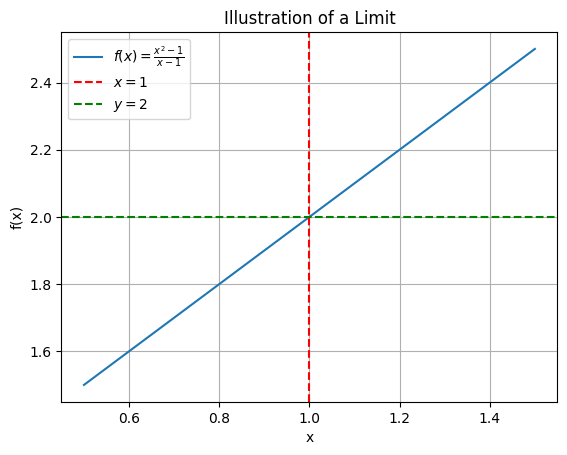

In [2]:
def f(x):
    return (x**2 - 1) / (x - 1)
a = 1
L = 2
epsilon = 0.01
delta = epsilon
x_values = np.array([
    0.99, 0.995, 0.999,
    1.001, 1.005, 1.009
])
for x in x_values:
    error = abs(f(x) - L)
    distance = abs(x - a)
    print(
        f"x = {x:.3f}, "
        f"|x - 1| = {distance:.4f}, "
        f"|f(x) - 2| = {error:.4f}, "
        f"Within epsilon: {error < epsilon}"
    )
#Plot
x = np.linspace(0.5, 1.5, 500)
# Exclude x = 1, where the function is undefined
x = x[x != 1]
y = f(x)
plt.plot(x, y, label=r"$f(x) = \frac{x^2-1}{x-1}$")
plt.axvline(1, color="red", linestyle="--", label=r"$x=1$")
plt.axhline(2, color="green", linestyle="--", label=r"$y=2$")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Illustration of a Limit")
plt.legend()
plt.grid(True)
plt.show()


### 3.2.2 Derivatives

Derivatives describe how a function changes with respect to its input variables. They are fundamental in optimization and data science, where they are used to study rates of change, identify extrema, and analyze functions of several variables.

#### 3.2.2.1 Single-Variable Case

**Definition 3.2.6 (Derivative).** Let $f:D\to\mathbb{R}$, where $D\subseteq\mathbb{R}$, and let $x_0\in D$ be an interior point of $D$. The derivative of $f$ at $x_0$ is defined as

$$
f'(x_0)=\frac{df(x_0)}{dx}
=\lim_{h\to 0}\frac{f(x_0+h)-f(x_0)}{h},
$$

provided that the limit exists.

**Theorem 3.2.9 (Rolle's Theorem).** Let $f:[a,b]\to\mathbb{R}$ be a continuous function whose derivative exists on $(a,b)$. If $f(a)=f(b)$, then there exists a point $c\in(a,b)$ such that

$$
f'(c)=0.
$$

**Theorem 3.2.10 (Mean Value Theorem).** Let $f:[a,b]\to\mathbb{R}$ be a continuous function whose derivative exists on $(a,b)$. Then there exists a point $c\in(a,b)$ such that

$$
f(b)=f(a)+(b-a)f'(c),
$$

or equivalently,

$$
\frac{f(b)-f(a)}{b-a}=f'(c).
$$

The mean value theorem states that the average rate of change of a function over an interval equals its instantaneous rate of change at some point within that interval.

Higher-order derivatives can be defined by differentiating a function repeatedly. If $f'$ exists on $D$, then $f'$ is itself a function of $x$. The second derivative of $f$ at an interior point $x_0\in D$ is defined as

$$
f''(x_0)=\frac{d^2f(x_0)}{dx^2}
=\lim_{h\to 0}\frac{f'(x_0+h)-f'(x_0)}{h},
$$

provided that the limit exists.

Numerical approximation of f'(x0)
Analytical derivative: f'(1.0) = 2.000000

h = 0.1000, approximation = 2.100000, error = 0.100000
h = 0.0100, approximation = 2.010000, error = 0.010000
h = 0.0010, approximation = 2.001000, error = 0.001000
h = 0.0001, approximation = 2.000100, error = 0.000100


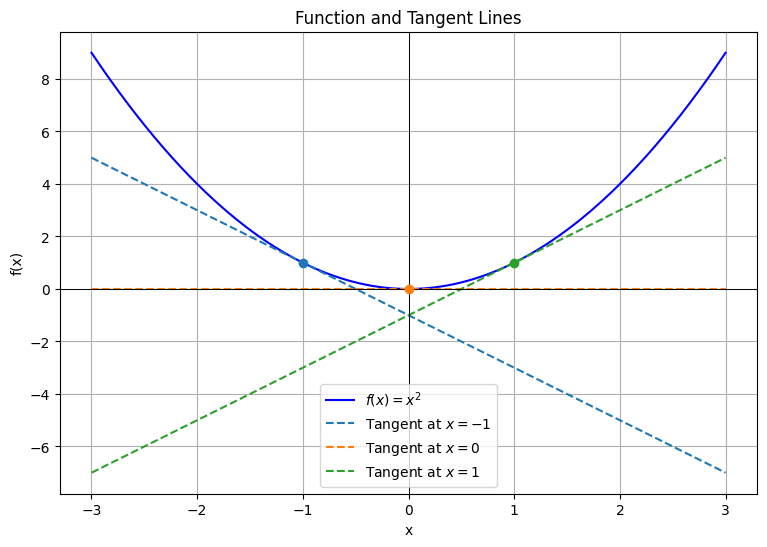


Mean Value Theorem
Interval: [-1.0, 2.0]
Average rate of change: 1.000000
Point c: 0.500000
Instantaneous rate f'(c): 1.000000

Rolle's Theorem
f(-2.0) = 4.0
f(2.0) = 4.0
f'(0.0) = 0.0


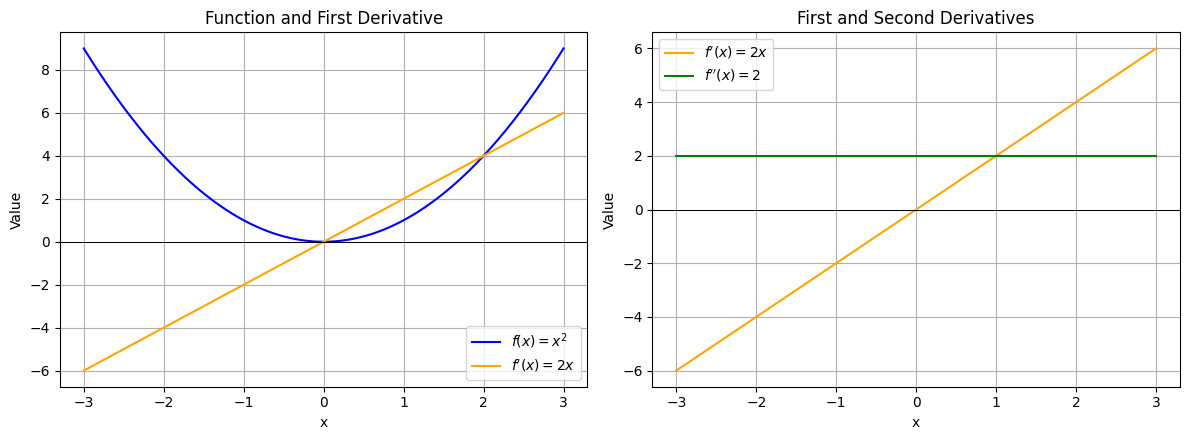

In [3]:
# Function and its analytical derivatives
def f(x):
    return x**2
def df(x):
    return 2*x
def d2f(x):
    return 2 + 0*x

# Numerical approximation of the derivative
x0 = 1.0
h_values = [0.1, 0.01, 0.001, 0.0001]
print("Numerical approximation of f'(x0)")
print(f"Analytical derivative: f'({x0}) = {df(x0):.6f}\n")
for h in h_values:
    numerical_derivative = (f(x0 + h) - f(x0)) / h
    print(
        f"h = {h:.4f}, "
        f"approximation = {numerical_derivative:.6f}, "
        f"error = {abs(numerical_derivative - df(x0)):.6f}"
    )

x = np.linspace(-3, 3, 500)
x_tangent = [-1, 0, 1]
plt.figure(figsize=(9, 6))
plt.plot(x, f(x), label=r"$f(x)=x^2$", color="blue")
for point in x_tangent:
    slope = df(point)
    tangent = f(point) + slope * (x - point)
    plt.plot(
        x, tangent, linestyle="--",
        label=fr"Tangent at $x={point}$"
    )
    plt.scatter(point, f(point), zorder=3)
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Function and Tangent Lines")
plt.axhline(0, color="black", linewidth=0.7)
plt.axvline(0, color="black", linewidth=0.7)
plt.grid(True)
plt.legend()
plt.show()


# Mean Value Theorem
a, b = -1.0, 2.0
average_rate = (f(b) - f(a)) / (b - a)
# For f(x)=x^2, f'(c)=2c
c = average_rate / 2
print("\nMean Value Theorem")
print(f"Interval: [{a}, {b}]")
print(f"Average rate of change: {average_rate:.6f}")
print(f"Point c: {c:.6f}")
print(f"Instantaneous rate f'(c): {df(c):.6f}")
# Rolle's theorem: choose endpoints with equal function values
a_rolle, b_rolle = -2.0, 2.0
c_rolle = 0.0
print("\nRolle's Theorem")
print(f"f({a_rolle}) = {f(a_rolle)}")
print(f"f({b_rolle}) = {f(b_rolle)}")
print(f"f'({c_rolle}) = {df(c_rolle)}")


fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(x, f(x), label=r"$f(x)=x^2$", color="blue")
axes[0].plot(x, df(x), label=r"$f'(x)=2x$", color="orange")
axes[0].axhline(0, color="black", linewidth=0.7)
axes[0].set_title("Function and First Derivative")
axes[0].set_xlabel("x")
axes[0].set_ylabel("Value")
axes[0].legend()
axes[0].grid(True)
axes[1].plot(x, df(x), label=r"$f'(x)=2x$", color="orange")
axes[1].plot(x, d2f(x), label=r"$f''(x)=2$", color="green")
axes[1].axhline(0, color="black", linewidth=0.7)
axes[1].set_title("First and Second Derivatives")
axes[1].set_xlabel("x")
axes[1].set_ylabel("Value")
axes[1].legend()
axes[1].grid(True)
plt.tight_layout()
plt.show()

#### 3.2.2.2 General Case

Many functions in data science involve several independent variables. Derivatives can be generalized to functions of several variables using partial derivatives and the Jacobian matrix.

**Definition 3.2.11 (Partial Derivative).** Let $f:D\to\mathbb{R}$, where $D\subseteq\mathbb{R}^d$, and let $x_0\in D$ be an interior point of $D$. The partial derivative of $f$ at $x_0$ with respect to the $ith$ coordinate is defined as

$$
\frac{\partial f(x_0)}{\partial x_i}
=\lim_{h\to 0}
\frac{f(x_0+he_i)-f(x_0)}{h},
$$

provided that the limit exists, where $e_i$ is the $i$th standard basis vector in $\mathbb{R}^d$.

**Definition 3.2.12 (Jacobian).** Let $f=(f_1,\ldots,f_m):D\to\mathbb{R}^m$, where $D\subseteq\mathbb{R}^d$, and let $x_0\in D$ be an interior point of $D$. Suppose that the partial derivatives $\partial f_j(x_0)/\partial x_i$ exist for all $i$ and $j$. The Jacobian of $f$ at $x_0$ is the $m\times d$ matrix

$$
J_f(x_0)=
\begin{pmatrix}
\frac{\partial f_1(x_0)}{\partial x_1}
&\cdots&
\frac{\partial f_1(x_0)}{\partial x_d}\\
\vdots&\ddots&\vdots\\
\frac{\partial f_m(x_0)}{\partial x_1}
&\cdots&
\frac{\partial f_m(x_0)}{\partial x_d}
\end{pmatrix}.
$$

For a real-valued function $f:D\to\mathbb{R}$, the Jacobian reduces to the row vector

$$
J_f(x_0)=\nabla f(x_0)^T,
$$

where

$$
\nabla f(x_0)=
\begin{pmatrix}
\frac{\partial f(x_0)}{\partial x_1}\\
\vdots\\
\frac{\partial f(x_0)}{\partial x_d}
\end{pmatrix}
$$

is the **gradient** of $f$ at $x_0$.

The chain rule provides a formula for calculating the Jacobian of a composition of functions. Let $h=g\circ f$, so that $h(x)=g(f(x))$.

**Theorem 3.2.15 (Chain Rule).** Let $f:D_1\to\mathbb{R}^m$, where $D_1\subseteq\mathbb{R}^d$, and let $g:D_2\to\mathbb{R}^p$, where $D_2\subseteq\mathbb{R}^m$. Suppose that $f$ is continuously differentiable at an interior point $x_0\in D_1$ and that $g$ is continuously differentiable at an interior point $f(x_0)\in D_2$. Then

$$
J_{g\circ f}(x_0)
=J_g(f(x_0))J_f(x_0),
$$

where the Jacobian of the composition is obtained by multiplying the corresponding Jacobian matrices.

#### 3.2.2.3 Further Derivatives

**Definition 3.2.16 (Directional Derivative).** Let $f:D\to\mathbb{R}$, where $D\subseteq\mathbb{R}^d$, let $x_0\in D$ be an interior point of $D$, and let $v\in\mathbb{R}^d$ be a unit vector. The directional derivative of $f$ at $x_0$ in the direction $v$ is defined as

$$
\frac{\partial f(x_0)}{\partial v}
=\lim_{h\to 0}
\frac{f(x_0+hv)-f(x_0)}{h},
$$

provided that the limit exists.

Taking $v=e_i$ recovers the $i$th partial derivative:

$$
\frac{\partial f(x_0)}{\partial e_i}
=\lim_{h\to 0}
\frac{f(x_0+he_i)-f(x_0)}{h}
=\frac{\partial f(x_0)}{\partial x_i}.
$$

**Theorem 3.2.17 (Directional Derivative from the Gradient).** Let $f:D\to\mathbb{R}$, where $D\subseteq\mathbb{R}^d$, let $x_0\in D$ be an interior point of $D$, and let $v\in\mathbb{R}^d$ be a unit vector. Suppose that $f$ is continuously differentiable at $x_0$. Then the directional derivative of $f$ at $x_0$ in the direction $v$ is given by

$$
\frac{\partial f(x_0)}{\partial v}
=J_f(x_0)v
=\nabla f(x_0)^T v.
$$

Thus, the directional derivative is the inner product of the gradient and the direction vector.

**Definition 3.2.18 (Second Partial Derivatives and Hessian).** Let $f:D\to\mathbb{R}$, where $D\subseteq\mathbb{R}^d$, and let $x_0\in D$ be an interior point of $D$. Suppose that $f$ is continuously differentiable in an open ball around $x_0$. The second partial derivative of $f$ at $x_0$, obtained by differentiating first with respect to $x_i$ and then with respect to $x_j$, is defined as

$$
\frac{\partial^2 f(x_0)}{\partial x_j\partial x_i}
=
\lim_{h\to 0}
\frac{
\frac{\partial f(x_0+he_j)}{\partial x_i}
-\frac{\partial f(x_0)}{\partial x_i}
}{h},
$$

provided that the limit exists.

When $j=i$, the second partial derivative is written as

$$
\frac{\partial^2 f(x_0)}{\partial x_i^2}.
$$

The Jacobian of the gradient $\nabla f$ is called the **Hessian matrix** and is denoted by $H_f(x_0)$. It is the $d\times d$ matrix of second partial derivatives:

$$
H_f(x_0)=
\begin{pmatrix}
\frac{\partial^2 f(x_0)}{\partial x_1^2}
&\cdots&
\frac{\partial^2 f(x_0)}{\partial x_d\partial x_1}\\
\vdots&\ddots&\vdots\\
\frac{\partial^2 f(x_0)}{\partial x_1\partial x_d}
&\cdots&
\frac{\partial^2 f(x_0)}{\partial x_d^2}
\end{pmatrix}.
$$

**Theorem 3.2.19 (Symmetry of the Hessian).** Let $f:D\to\mathbb{R}$, where $D\subseteq\mathbb{R}^d$, and let $x_0\in D$ be an interior point of $D$. Suppose that $f$ is twice continuously differentiable at $x_0$. Then, for all $i\neq j$,

$$
\frac{\partial^2 f(x_0)}{\partial x_j\partial x_i}
=
\frac{\partial^2 f(x_0)}{\partial x_i\partial x_j}.
$$

Consequently, the Hessian matrix is symmetric whenever the second partial derivatives are continuous.

PARTIAL DERIVATIVES
Point: (1.0, 2.0)
Analytical df/dx: 4.000000
Numerical df/dx:  4.000010
Analytical df/dy: 9.000000
Numerical df/dy:  9.000020

GRADIENT
[4. 9.]

JACOBIAN OF F(x,y) = (x^2+y, xy)
[[2. 1.]
 [2. 1.]]

CHAIN RULE
Jacobian using chain rule:
[[10.  5.]]
Direct analytical derivative:
[10.  5.]

DIRECTIONAL DERIVATIVE
Unit direction: [0.70710678 0.70710678]
Analytical: 9.192388
Numerical:  9.192408

HESSIAN
[[2 1]
 [1 4]]
Eigenvalues: [1.58578644 4.41421356]
Determinant: 7.000000


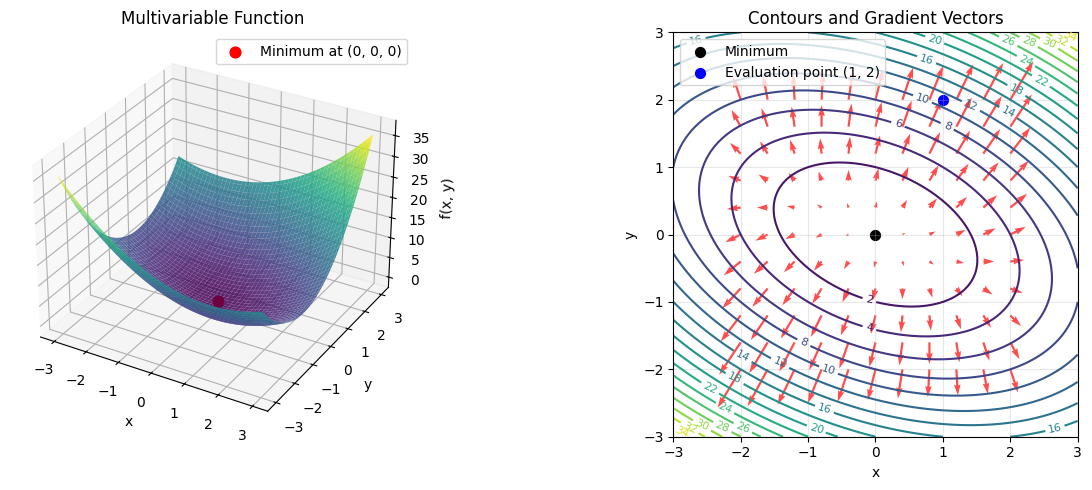

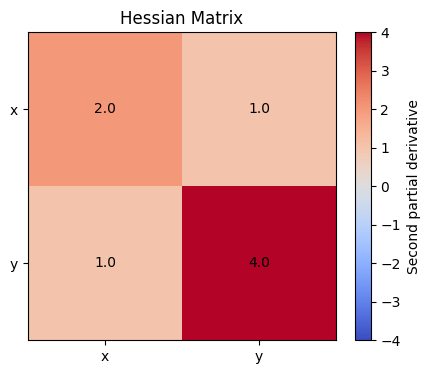

In [4]:
# Define the multivariable function and derivatives
def f(x, y):
    return x**2 + x*y + 2*y**2
def df_dx(x, y):
    return 2*x + y
def df_dy(x, y):
    return x + 4*y
def gradient(x, y):
    return np.array([df_dx(x, y), df_dy(x, y)])
def jacobian_F(x, y):
    return np.array([
        [2*x, 1],
        [y, x]
    ])
def hessian(x, y):
    return np.array([
        [2, 1],
        [1, 4]
    ])
# Numerical approximation of partial derivatives
x0, y0 = 1.0, 2.0
h = 1e-5
partial_x_num = (
    f(x0 + h, y0) - f(x0, y0)
) / h
partial_y_num = (
    f(x0, y0 + h) - f(x0, y0)
) / h
print("PARTIAL DERIVATIVES")
print(f"Point: ({x0}, {y0})")
print(f"Analytical df/dx: {df_dx(x0, y0):.6f}")
print(f"Numerical df/dx:  {partial_x_num:.6f}")
print(f"Analytical df/dy: {df_dy(x0, y0):.6f}")
print(f"Numerical df/dy:  {partial_y_num:.6f}")
print("\nGRADIENT")
print(gradient(x0, y0))
print("\nJACOBIAN OF F(x,y) = (x^2+y, xy)")
print(jacobian_F(x0, y0))

# Chain rule
# F(x,y) = (x^2+y, xy)
# g(u,v) = u+v^2
# h(x,y) = g(F(x,y))
def h_composed(x, y):
    u = x**2 + y
    v = x*y
    return u + v**2
def grad_h_analytical(x, y):
    return np.array([
        2*x + 2*x*y**2,
        1 + 2*x**2*y
    ])
# Jacobian of g at F(x,y)
u = x0**2 + y0
v = x0 * y0
J_g = np.array([[1, 2*v]])
# Chain rule: J_h = J_g @ J_F
J_h_chain = J_g @ jacobian_F(x0, y0)
print("\nCHAIN RULE")
print("Jacobian using chain rule:")
print(J_h_chain)
print("Direct analytical derivative:")
print(grad_h_analytical(x0, y0))

# Directional derivative
direction = np.array([1.0, 1.0])
direction = direction / np.linalg.norm(direction)
directional_analytical = gradient(x0, y0) @ direction
point = np.array([x0, y0])
directional_numerical = (
    f(*(point + h * direction)) - f(x0, y0)
) / h
print("\nDIRECTIONAL DERIVATIVE")
print(f"Unit direction: {direction}")
print(f"Analytical: {directional_analytical:.6f}")
print(f"Numerical:  {directional_numerical:.6f}")

# Hessian and curvature
H = hessian(x0, y0)
eigenvalues = np.linalg.eigvalsh(H)
print("\nHESSIAN")
print(H)
print(f"Eigenvalues: {eigenvalues}")
print(f"Determinant: {np.linalg.det(H):.6f}")

# Visualize the function and its gradient
x = np.linspace(-3, 3, 100)
y = np.linspace(-3, 3, 100)
X, Y = np.meshgrid(x, y)
Z = f(X, Y)
fig = plt.figure(figsize=(14, 5))
# Surface plot
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
ax1.plot_surface(X, Y, Z, cmap="viridis", alpha=0.85)
ax1.scatter(0, 0, 0, color="red", s=60,
            label="Minimum at (0, 0, 0)")
ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.set_zlabel("f(x, y)")
ax1.set_title("Multivariable Function")
ax1.legend()
# Contour plot with gradient vectors
ax2 = fig.add_subplot(1, 2, 2)
contours = ax2.contour(X, Y, Z, levels=20, cmap="viridis")
ax2.clabel(contours, inline=True, fontsize=8)
grid_points = np.linspace(-2, 2, 11)
GX, GY = np.meshgrid(grid_points, grid_points)
U = df_dx(GX, GY)
V = df_dy(GX, GY)
ax2.quiver(GX, GY, U, V, color="red", alpha=0.7)
ax2.scatter(0, 0, color="black", s=50, label="Minimum")
ax2.scatter(x0, y0, color="blue", s=50,
            label="Evaluation point (1, 2)")
ax2.set_xlabel("x")
ax2.set_ylabel("y")
ax2.set_title("Contours and Gradient Vectors")
ax2.set_aspect("equal")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# Visualize the Hessian
plt.figure(figsize=(5, 4))
plt.imshow(H, cmap="coolwarm", vmin=-4, vmax=4)
plt.colorbar(label="Second partial derivative")
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        plt.text(j, i, f"{H[i, j]:.1f}",
                 ha="center", va="center", color="black")
plt.xticks([0, 1], ["x", "y"])
plt.yticks([0, 1], ["x", "y"])
plt.title("Hessian Matrix")
plt.show()


### 3.2.3 Taylor’s Theorem
Taylor’s theorem provides an approximation of a function using its derivatives at a given point. It is useful for analyzing the local behavior of functions and is widely used in optimization and the study of functions of several variables.

**Theorem 3.2.21 (Taylor’s Theorem).** Let $f:D\to\mathbb{R}$, where $D\subseteq\mathbb{R}$, and suppose that $f$ has $m$ continuous derivatives on $[a,b]$. Then

$$
\begin{aligned}
f(b)={}&f(a)+(b-a)f'(a)+\frac{(b-a)^2}{2!}f''(a)+\cdots+\frac{(b-a)^{m-1}}{(m-1)!}f^{(m-1)}(a)+R_m,
\end{aligned}
$$

where the remainder term is

$$
R_m=\frac{(b-a)^m}{m!}f^{(m)}(a+\theta(b-a))
$$

for some $\theta\in(0,1)$.

In particular, for $m=2$, we have

$$
f(b)=f(a)+(b-a)f'(a)
+\frac{1}{2}(b-a)^2f''(\xi),
\tag{3.2.2}
$$

for some $\xi\in(a,b)$.

**Theorem 3.2.22 (Multivariate Mean Value Theorem).** Let $f:D\to\mathbb{R}$, where $D\subseteq\mathbb{R}^d$. Let $x_0\in D$ and $\delta>0$ be such that $B_\delta(x_0)\subseteq D$. If $f$ is continuously differentiable on $B_\delta(x_0)$, then, for any $x\in B_\delta(x_0)$,

$$
f(x)=f(x_0)+\nabla f(x_0+\xi p)^T p,
\tag{3.2.3}
$$

for some $\xi\in(0,1)$, where

$$
p=x-x_0.
$$

**Theorem 3.2.23 (Multivariate Taylor Theorem).** Let $f:D\to\mathbb{R}$, where $D\subseteq\mathbb{R}^d$. Let $x_0\in D$ and $\delta>0$ be such that $B_\delta(x_0)\subseteq D$. If $f$ is three times continuously differentiable on $B_\delta(x_0)$, then, for any $x\in B_\delta(x_0)$,

$$
f(x)=f(x_0)+\nabla f(x_0)^T p
+\frac{1}{2}p^T H_f(x_0)p
+O(\|p\|^3),
\tag{3.2.4}
$$

where $p=x-x_0$ and $H_f(x_0)$ is the Hessian matrix of $f$ at $x_0$.

If $f$ is twice continuously differentiable on $B_\delta(x_0)$, then, for any $x\in B_\delta(x_0)$,

$$
f(x)=f(x_0)+\nabla f(x_0)^T p
+\frac{1}{2}p^T H_f(x_0+\xi p)p,
\tag{3.2.5}
$$

for some $\xi\in(0,1)$, where $p=x-x_0$.

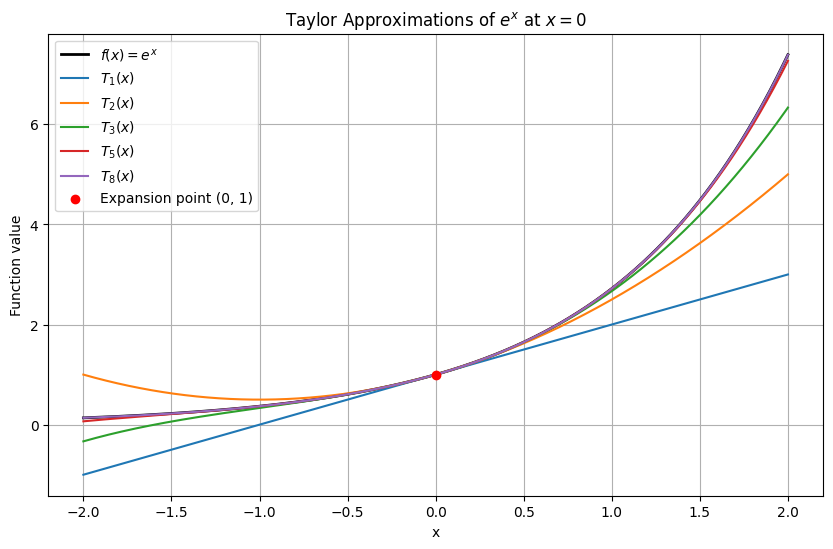

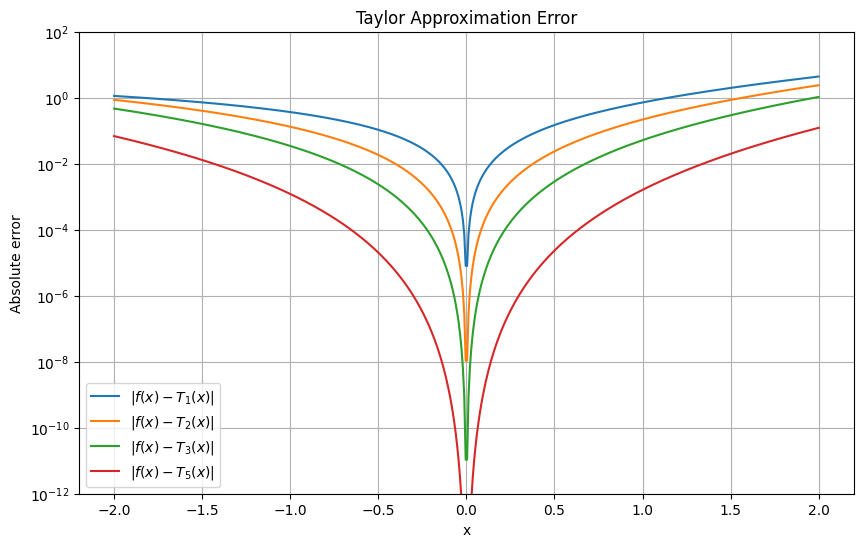

Approximation errors for exp(x)

x = 0.1
  Degree 1: approximation = 1.10000000, error = 5.171e-03
  Degree 2: approximation = 1.10500000, error = 1.709e-04
  Degree 3: approximation = 1.10516667, error = 4.251e-06
  Degree 5: approximation = 1.10517092, error = 1.409e-09

x = 0.5
  Degree 1: approximation = 1.50000000, error = 1.487e-01
  Degree 2: approximation = 1.62500000, error = 2.372e-02
  Degree 3: approximation = 1.64583333, error = 2.888e-03
  Degree 5: approximation = 1.64869792, error = 2.335e-05

x = 1.0
  Degree 1: approximation = 2.00000000, error = 7.183e-01
  Degree 2: approximation = 2.50000000, error = 2.183e-01
  Degree 3: approximation = 2.66666667, error = 5.162e-02
  Degree 5: approximation = 2.71666667, error = 1.615e-03

x = 1.5
  Degree 1: approximation = 2.50000000, error = 1.982e+00
  Degree 2: approximation = 3.62500000, error = 8.567e-01
  Degree 3: approximation = 4.18750000, error = 2.942e-01
  Degree 5: approximation = 4.46171875, error = 1.997e-02


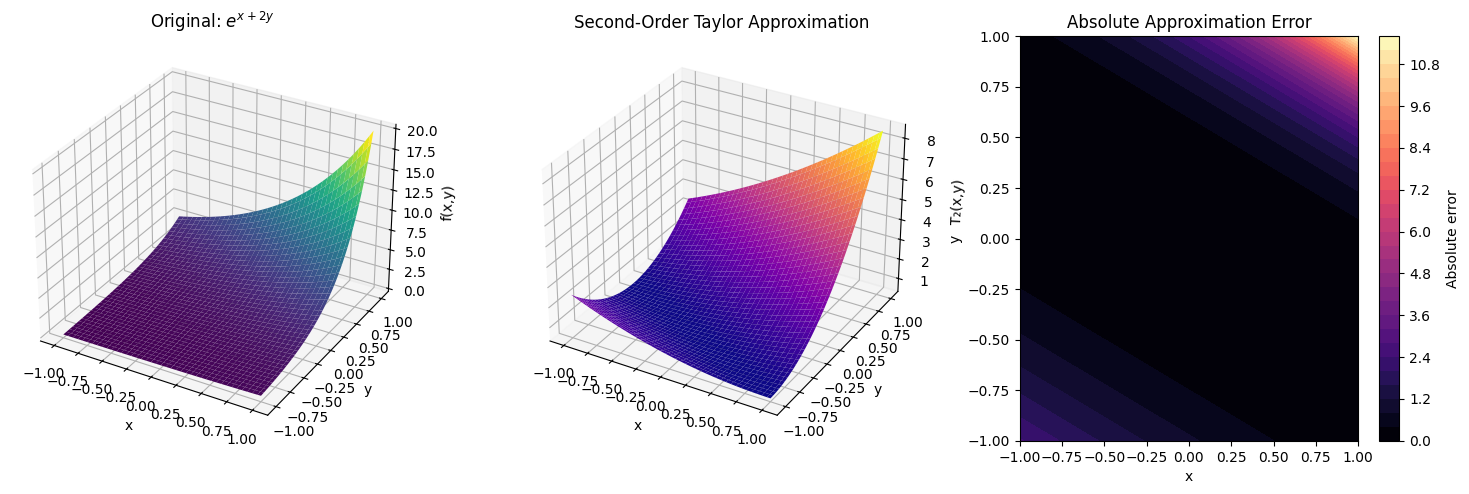


Multivariate Taylor approximation errors
(x,y)=(0.05,0.05), actual=1.16183424, approximation=1.16125000, error=5.842e-04
(x,y)=(0.10,0.10), actual=1.34985881, approximation=1.34500000, error=4.859e-03
(x,y)=(0.25,0.25), actual=2.11700002, approximation=2.03125000, error=8.575e-02
(x,y)=(0.50,0.50), actual=4.48168907, approximation=3.62500000, error=8.567e-01


In [5]:
from math import factorial
# Function and Taylor polynomials
def f(x):
    return np.exp(x)
def taylor_exp(x, n):
    """Taylor polynomial of exp(x) about x = 0."""
    result = np.zeros_like(np.asarray(x, dtype=float))
    for k in range(n + 1):
        result += np.asarray(x, dtype=float)**k / factorial(k)
    return result
# Plot interval
x = np.linspace(-2, 2, 500)
y = f(x)

# Compare Taylor approximations
plt.figure(figsize=(10, 6))
plt.plot(x, y, color="black", linewidth=2,
         label=r"$f(x)=e^x$")
for n in [1, 2, 3, 5, 8]:
    plt.plot(x, taylor_exp(x, n),
             label=fr"$T_{n}(x)$")
plt.scatter(0, 1, color="red", zorder=5,
            label="Expansion point (0, 1)")
plt.xlabel("x")
plt.ylabel("Function value")
plt.title("Taylor Approximations of $e^x$ at $x=0$")
plt.grid(True)
plt.legend()
plt.show()

# Examine approximation errors
plt.figure(figsize=(10, 6))
for n in [1, 2, 3, 5]:
    error = np.abs(y - taylor_exp(x, n))
    plt.plot(x, error, label=fr"$|f(x)-T_{n}(x)|$")
plt.xlabel("x")
plt.ylabel("Absolute error")
plt.title("Taylor Approximation Error")
plt.yscale("log")
plt.ylim(1e-12, 1e2)
plt.grid(True)
plt.legend()
plt.show()
# Numerical error at selected points
print("Approximation errors for exp(x)")
for point in [0.1, 0.5, 1.0, 1.5]:
    print(f"\nx = {point}")
    for n in [1, 2, 3, 5]:
        approximation = taylor_exp(point, n)
        error = abs(np.exp(point) - approximation)
        print(f"  Degree {n}: approximation = "
              f"{approximation:.8f}, error = {error:.3e}")

# 4. Multivariate Taylor approximation
# f(x,y) = exp(x + 2y), expanded around (0,0)
def f_multi(x, y):
    return np.exp(x + 2*y)
def taylor_multi_2(x, y):
    s = x + 2*y
    return 1 + s + 0.5*s**2
x_grid = np.linspace(-1, 1, 120)
y_grid = np.linspace(-1, 1, 120)
X, Y = np.meshgrid(x_grid, y_grid)
Z = f_multi(X, Y)
Z_approx = taylor_multi_2(X, Y)
Z_error = np.abs(Z - Z_approx)

# 5. Visualize original function and approximation
fig = plt.figure(figsize=(15, 5))
ax1 = fig.add_subplot(1, 3, 1, projection="3d")
ax1.plot_surface(X, Y, Z, cmap="viridis",
                 linewidth=0, antialiased=True)
ax1.set_title(r"Original: $e^{x+2y}$")
ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.set_zlabel("f(x,y)")
ax2 = fig.add_subplot(1, 3, 2, projection="3d")
ax2.plot_surface(X, Y, Z_approx, cmap="plasma",
                 linewidth=0, antialiased=True)
ax2.set_title("Second-Order Taylor Approximation")
ax2.set_xlabel("x")
ax2.set_ylabel("y")
ax2.set_zlabel("T₂(x,y)")
ax3 = fig.add_subplot(1, 3, 3)
contour = ax3.contourf(X, Y, Z_error, levels=30,
                       cmap="magma")
fig.colorbar(contour, ax=ax3, label="Absolute error")
ax3.set_title("Absolute Approximation Error")
ax3.set_xlabel("x")
ax3.set_ylabel("y")
plt.tight_layout()
plt.show()

# Compare accuracy near the expansion point
test_points = [
    (0.05, 0.05),
    (0.1, 0.1),
    (0.25, 0.25),
    (0.5, 0.5)
]
print("\nMultivariate Taylor approximation errors")
for px, py in test_points:
    actual = f_multi(px, py)
    approximate = taylor_multi_2(px, py)
    error = abs(actual - approximate)
    print(
        f"(x,y)=({px:.2f},{py:.2f}), "
        f"actual={actual:.8f}, "
        f"approximation={approximate:.8f}, "
        f"error={error:.3e}"
    )